# PhishGuard-ML: 04 - Evaluation and Risk Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

## 1. Load Data and Models

In [2]:
def shift_features(X):
    return X + 1

X_test = pd.read_csv("data/X_test.csv")
y_test = pd.read_csv("data/y_test.csv")['Result']

# Load models
models = {}
model_files = [f for f in os.listdir("models") if f.endswith(".pkl")]

for f in model_files:
    # Reverse the filename transformation to get model name
    name = f.replace(".pkl", "").replace("_", " ").title()
    if name.lower() == "knn": name = "KNN"
    if name.lower() == "svm": name = "SVM"
    models[name] = joblib.load(f"models/{f}")

print(f"Loaded {len(models)} models: {list(models.keys())}")

Loaded 4 models: ['Categorical Naive Bayes', 'Decision Tree', 'KNN', 'SVM']


## 2. Evaluation 

In [3]:
results = []
conf_matrices = {}
roc_curves = {}

for name, model in models.items():
    pred = model.predict(X_test)
    
    # Store confusion matrix
    cm = confusion_matrix(y_test, pred)
    conf_matrices[name] = cm
    
    # Get probabilities for ROC AUC (if supported)
    if hasattr(model, "predict_proba"):
        pred_prob = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, pred_prob)
        fpr, tpr, _ = roc_curve(y_test, pred_prob)
        roc_curves[name] = (fpr, tpr, auc)
    else:
        auc = np.nan
        
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": auc
    })
    
    print(f"\n{'='*30}\n{name}\n{'='*30}")
    print(classification_report(y_test, pred))

results_df = pd.DataFrame(results)
print("\n--- Summary Model Comparison ---")
print(results_df.sort_values("F1-score", ascending=False).to_string(index=False))


Categorical Naive Bayes
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      1231
           1       0.94      0.91      0.92       980

    accuracy                           0.93      2211
   macro avg       0.93      0.93      0.93      2211
weighted avg       0.93      0.93      0.93      2211


Decision Tree
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      1231
           1       0.97      0.96      0.97       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211




KNN
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1231
           1       0.98      0.95      0.96       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211




SVM
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      1231
           1       0.97      0.96      0.96       980

    accuracy                           0.97      2211
   macro avg       0.97      0.97      0.97      2211
weighted avg       0.97      0.97      0.97      2211


--- Summary Model Comparison ---
                  Model  Accuracy  Precision   Recall  F1-score  ROC-AUC
          Decision Tree  0.970149   0.973085 0.959184  0.966084 0.977793
                    SVM  0.967888   0.971963 0.955102  0.963459 0.993709
                    KNN  0.967888   0.975916 0.951020  0.963307 0.988869
Categorical Naive Bayes  0.933062   0.937895 0.909184  0.923316 0.981440


## 3. Visualizing Confusion Matrices

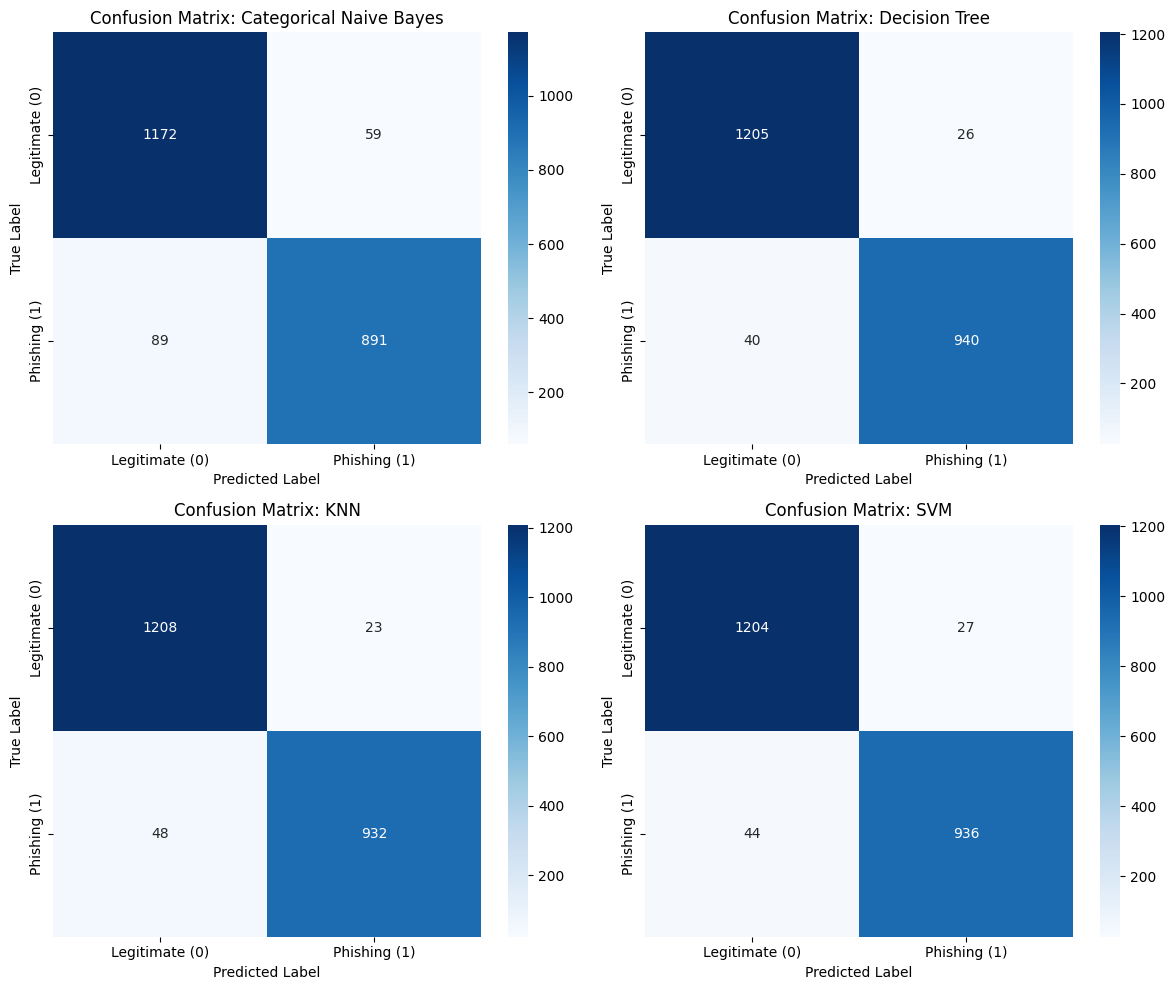

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, cm) in enumerate(conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], 
                xticklabels=['Legitimate (0)', 'Phishing (1)'],
                yticklabels=['Legitimate (0)', 'Phishing (1)'])
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()

## 4. ROC Curves Comparison

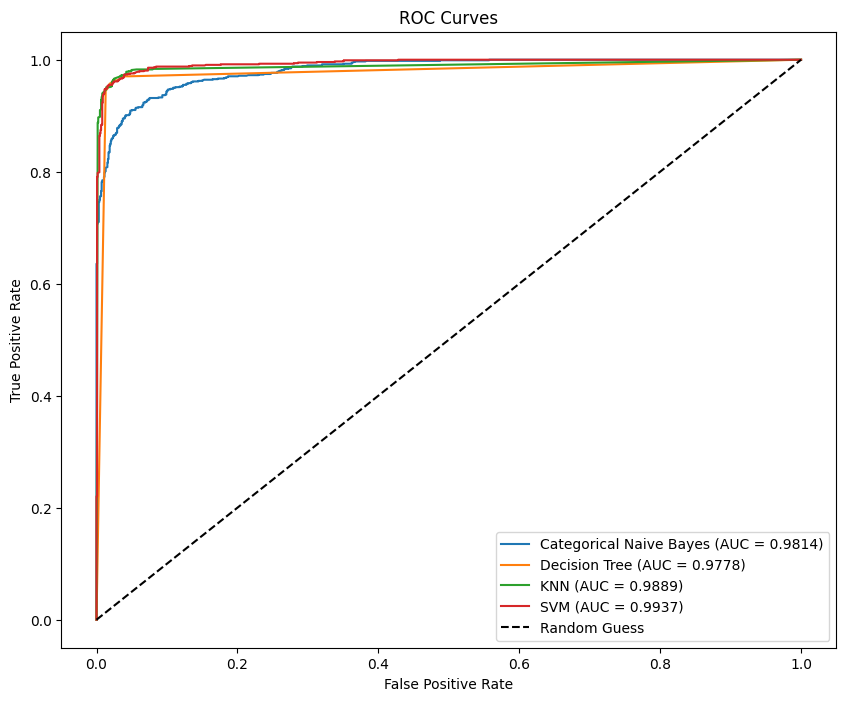

In [5]:
plt.figure(figsize=(10, 8))

for name, (fpr, tpr, auc) in roc_curves.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right')
plt.show()

## 5. Error Analysis (False Positives and False Negatives)

In phishing detection:
- **False Positive**: A legitimate website classified as phishing. (Inconvenience, warning user unnecessarily)
- **False Negative**: A phishing website classified as legitimate. (High Risk, user may lose credentials/money)

Thus, high **Recall** is extremely important to minimize False Negatives.

In [6]:
best_model_row = results_df.sort_values("Recall", ascending=False).iloc[0]
print(f"The best model for minimizing False Negatives (highest Recall) is {best_model_row['Model']} "
      f"with Recall: {best_model_row['Recall']:.4f}")

The best model for minimizing False Negatives (highest Recall) is Decision Tree with Recall: 0.9592
